In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("house_price_prediction.csv")
df.shape

(7045, 13)

# Proyecto N-3: Inversión Inmobiliaria
## Fase 2: Adquisición de Datos
Contexto: cargamos el dataset House Price Prediction (Kaggle)

Revisar la estructura del df, el formato valores únicos y posibles replicados de cada columna.

In [ ]:
#Información del df
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7045 entries, 0 to 7044
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   House_ID                    7045 non-null   int64  
 1   Property_Code               7045 non-null   object 
 2   Area_Sqft                   6835 non-null   float64
 3   Bedrooms                    7045 non-null   int64  
 4   Bathrooms                   7045 non-null   int64  
 5   Age_Years                   6835 non-null   float64
 6   Location                    7045 non-null   object 
 7   Furnishing_Status           6835 non-null   object 
 8   Property_Type               7045 non-null   object 
 9   Parking_Spaces              7045 non-null   int64  
 10  Garden_Available            7045 non-null   int64  
 11  Distance_To_City_Center_Km  6833 non-null   float64
 12  Price                       7045 non-null   float64
dtypes: float64(4), int64(5), object(4

In [ ]:
#Columnas con valores vacíos
print(df.isnull().sum())

House_ID                        0
Property_Code                   0
Area_Sqft                     210
Bedrooms                        0
Bathrooms                       0
Age_Years                     210
Location                        0
Furnishing_Status             210
Property_Type                   0
Parking_Spaces                  0
Garden_Available                0
Distance_To_City_Center_Km    212
Price                           0
dtype: int64


In [ ]:
#Distribución de variable objetivo
df['Price'].describe()

,Price
count,7.045000e+03
mean,5.192220e+05
std,1.394974e+05
min,7.071700e+04
25%,4.275810e+05
50%,5.126030e+05
75%,6.002990e+05
max,1.768638e+06


In [ ]:
#Columnas
df.head(3)

,House_ID,Property_Code,Area_Sqft,Bedrooms,Bathrooms,Age_Years,Location,Furnishing_Status,Property_Type,Parking_Spaces,Garden_Available,Distance_To_City_Center_Km,Price
0,1,HP-2018-10000,2548.0,1,1,5.0,Urban,Semi-Furnished,Studio,3,0,3.6,428225.0
1,2,HP-2019-10001,2103.0,2,1,2.0,Suburban,Semi-Furnished,Apartment,1,0,1.3,414559.0
2,3,HP-2020-10002,2653.0,3,2,3.0,Urban,Semi-Furnished,Apartment,2,0,3.0,560716.0


In [ ]:
# Categorías ocn duplicados
print(df['Furnishing_Status'].unique())
print(df['Location'].unique())
print(df['Property_Type'].unique())

['Semi-Furnished' '#Semi-Furnished' 'Unfurnished' 'Furnished'
 'Un-furnished' 'Furnished ' 'FURNISHED' 'Semi_Furnished' nan
 'semi-furnished' ' Unfurnished' ' Furnished' 'SEMI-FURNISHED'
 '#Unfurnished' 'Semi Furnished' 'UNFURNISHED' 'unfurnished' 'furnished'
 '#Furnished']
['Urban' 'Suburban' 'Rural' 'Downtown']
['Studio' 'Apartment' 'Villa' 'Independent House']


## Hallazgos:
- 4 columnas con nulos (~210 cada una): Area_Sqft, Age_Years, Furnishing_Status, Distance_To_City_Center_Km.
- Furnishing_Status tiene 18 variantes que representan solo 3 categorías reales (Furnished, Semi-Furnished, Unfurnished) + nulos.
- Price va de ~70k a ~1.76M; media > mediana → asimetría positiva (revisar en F-4).
- House_ID y Property_Code son identificadores, se excluirán del modelado.
- Pendiente de verificar: duplicados, outliers, tipos incorrectos en otras columnas.

## Decisión N-3
- 1: Exclusión de identificadores
- Contexto: el dataset incluye House_ID y Property_Code.
- Opciones evaluadas: incluirlos como predictores / excluirlos.
- Decisión tomada: excluirlos ya que son identificadores únicos, no describen la vivienda; inducirían memorización (leakage).


## Fase 3.- Limpieza de Datos

Una vez que el problema se ha entendido y se sabe qué contiene el dataframe, es hora de abordar y solucionar los problemas que éste tiene para poder interpretar correctamente el mismo antes de preparar cualquier modelo.

In [ ]:
#Diagnóstico completo de problemas de calidad.
print(f"El número de filas duplicadas en el df es de: {df.duplicated().sum()}")
print(f"Las columnas con valores nulos son:\n{df.isnull().sum()[df.isnull().sum()>0]}")
print(f"Lo cuál representa el porcentaje de:\n{(df.isnull().mean() * 100)[lambda x: x > 0]}")
print(df[['Price','Area_Sqft']].head(3))
print(df['Furnishing_Status'].unique())
print(df['Location'].unique())
print(df['Property_Type'].unique())
print(df.describe())
seriea = df['Area_Sqft'].dropna()
q1a, q3a = np.percentile(seriea, [25,75])
iqra = q3a - q1a
lim_infa = q1a - 1.5 * iqra
lim_supa = q3a + 1.5 * iqra
n_outliersa = ((seriea < lim_infa)|(seriea > lim_supa)).sum()
serieay = df['Age_Years'].dropna()
q1ay, q3ay = np.percentile(serieay, [25,75])
iqray = q3ay - q1ay
lim_infay = q1ay - 1.5 * iqray
lim_supay = q3ay + 1.5 * iqray
n_outliersay = ((serieay < lim_infay)|(serieay > lim_supay)).sum()
seried = df['Distance_To_City_Center_Km'].dropna()
q1d, q3d = np.percentile(seried, [25,75])
iqrd = q3d - q1d
lim_infd = q1d - 1.5 * iqrd
lim_supd = q3d + 1.5 * iqrd
n_outliersd = ((seriea < lim_infa)|(seriea > lim_supa)).sum()
print(f"El número de outliers de la columna 'Area_Sqft' es:{n_outliersa}")
print(f"El número de outliers de la columna 'Age_Years' es:{n_outliersay}")
print(f"El número de outliers de la columnas 'Distance_To_City_Center_Km' es:{n_outliersd}")

El número de filas duplicadas en el df es de: 44
Las columnas con valores nulos son:
Area_Sqft                     210
Age_Years                     210
Furnishing_Status             210
Distance_To_City_Center_Km    212
dtype: int64
Lo cuál representa el porcentaje de:
Area_Sqft                     2.980837
Age_Years                     2.980837
Furnishing_Status             2.980837
Distance_To_City_Center_Km    3.009226
dtype: float64
      Price  Area_Sqft
0  428225.0     2548.0
1  414559.0     2103.0
2  560716.0     2653.0
['Semi-Furnished' '#Semi-Furnished' 'Unfurnished' 'Furnished'
 'Un-furnished' 'Furnished ' 'FURNISHED' 'Semi_Furnished' nan
 'semi-furnished' ' Unfurnished' ' Furnished' 'SEMI-FURNISHED'
 '#Unfurnished' 'Semi Furnished' 'UNFURNISHED' 'unfurnished' 'furnished'
 '#Furnished']
['Urban' 'Suburban' 'Rural' 'Downtown']
['Studio' 'Apartment' 'Villa' 'Independent House']
          House_ID     Area_Sqft     Bedrooms    Bathrooms    Age_Years  \
count  7045.000000   6835

In [ ]:
#Duplicados.
print(df.duplicated().sum(), df.shape)
print(df.drop_duplicates(inplace=True))
print(df.duplicated().sum(), df.shape)




44 (7045, 13)
None
0 (7001, 13)


In [ ]:
#Nulos.
df[['Area_Sqft','Age_Years','Distance_To_City_Center_Km']].describe()


,Area_Sqft,Age_Years,Distance_To_City_Center_Km
count,6791.000000,6791.000000,6791.000000
mean,2228.097360,12.018882,8.221406
std,798.489492,12.205680,8.801817
min,500.000000,0.000000,0.500000
25%,1732.000000,3.000000,2.300000
50%,2201.000000,8.000000,5.500000
75%,2677.000000,16.000000,11.300000
max,10901.358123,108.084513,215.994605


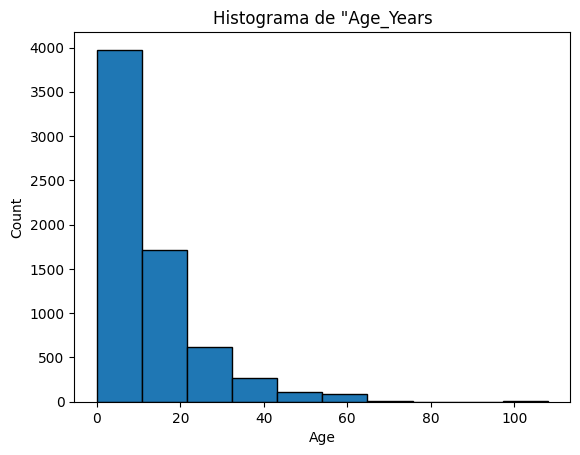

In [ ]:
plt.hist(df['Age_Years'],edgecolor='black')
plt.title('Histograma de "Age_Years')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

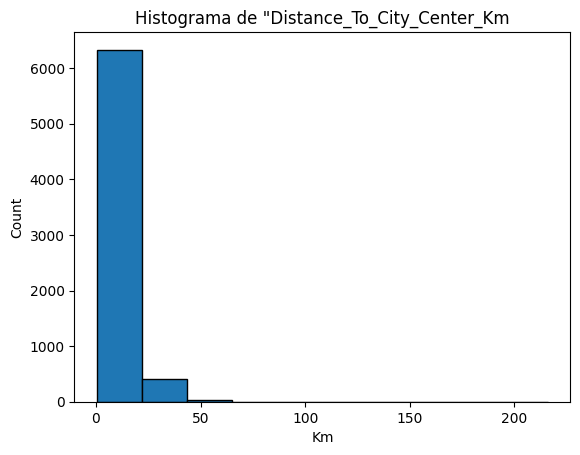

In [ ]:
plt.hist(df['Distance_To_City_Center_Km'],edgecolor='black')
plt.title('Histograma de "Distance_To_City_Center_Km')
plt.xlabel('Km')
plt.ylabel('Count')
plt.show()

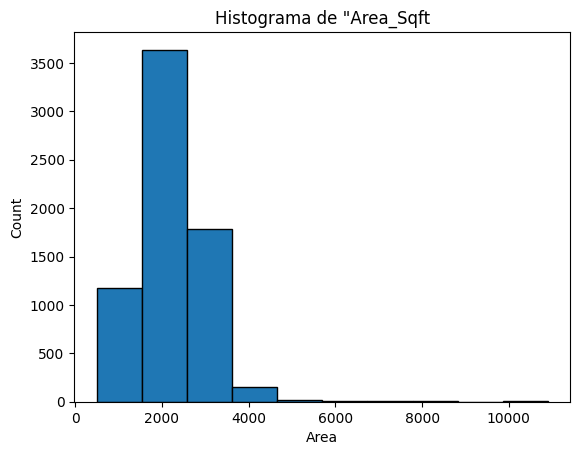

In [ ]:
plt.hist(df['Area_Sqft'],edgecolor='black')
plt.title('Histograma de "Area_Sqft')
plt.xlabel('Area')
plt.ylabel('Count')
plt.show()

In [ ]:
print(df['Furnishing_Status'].value_counts())

Furnishing_Status
Semi-Furnished     2336
Unfurnished        1778
Furnished          1644
SEMI-FURNISHED       94
semi-furnished       92
Semi_Furnished       89
furnished            85
#Semi-Furnished      82
Furnished            71
Semi Furnished       71
 Unfurnished         64
 Furnished           64
unfurnished          59
FURNISHED            58
UNFURNISHED          56
#Furnished           52
Un-furnished         48
#Unfurnished         48
Name: count, dtype: int64


In [ ]:
#Imputación de valores nulos
df['Age_Years'] = df['Age_Years'].fillna(df['Age_Years'].median())
df['Area_Sqft'] = df['Area_Sqft'].fillna(df['Area_Sqft'].median())
df['Distance_To_City_Center_Km'] = df['Distance_To_City_Center_Km'].fillna(df['Distance_To_City_Center_Km'].median())
df['Furnishing_Status'] = df['Furnishing_Status'].fillna(df['Furnishing_Status'].mode()[0])
print(df.isnull().sum())

House_ID                      0
Property_Code                 0
Area_Sqft                     0
Bedrooms                      0
Bathrooms                     0
Age_Years                     0
Location                      0
Furnishing_Status             0
Property_Type                 0
Parking_Spaces                0
Garden_Available              0
Distance_To_City_Center_Km    0
Price                         0
dtype: int64


In [ ]:
#Categorías sucias
df['Furnishing_Status'] = df['Furnishing_Status'].str.lower().str.strip()
df['Furnishing_Status'] = df['Furnishing_Status'].str.replace(r'[^a-z]','_',regex=True)
#Eliminar caracter que no sea letra al inicio
df['Furnishing_Status'] = df['Furnishing_Status'].str.replace(r'^[^a-z]+','',regex=True)
#ELimina caracter que no sea letra el final
df['Furnishing_Status'] = df['Furnishing_Status'].str.replace(r'[^a-z]+$','',regex=True)
df['Furnishing_Status'] = df['Furnishing_Status'].str.replace('un_furnished','unfurnished')
print(df['Furnishing_Status'].unique())



['semi_furnished' 'unfurnished' 'furnished']


# EDA

En F-3 el dataset quedó limpio: sin duplicados, sin nulos, con Furnishing_Status normalizado y 7001 filas × 13 columnas. Pero limpio no significa entendido.

F-4 es donde se responde a  la pregunta: ¿qué me están diciendo estos datos? Antes de entrenar cualquier modelo (F-5), se necesita saber:

* Cómo se distribuye Price (la variable que vas a predecir).

* Qué variables parecen estar más relacionadas con Price.

* Si hay variables redundantes entre sí (multicolinealidad).

* Si quedan outliers que puedan distorsionar el modelo.

## 1. ¿Por qué es importante la distribución de Price?

Porque Price es la variable que el modelo va a predecir. Su forma determina:

Qué modelos funcionarán mejor. Muchos modelos lineales asumen que los residuos se distribuyen de forma aproximadamente normal. Si Price está muy sesgada, esa suposición se rompe.

Si conviene transformarla. Aplicar log(Price) suele "enderezar" distribuciones sesgadas a la derecha y mejorar el RMSE en F-5.

Qué métrica de error esperar. Si Price tiene cola larga (pocas casas muy caras), el RMSE se disparará con esas casas. Saberlo te prepara para interpretar el resultado.

En resumen: la distribución de Price condiciona decisiones de modelado en F-5, no solo es un dato descriptivo.

In [ ]:
num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(num_cols)
print(cat_cols)

['House_ID', 'Area_Sqft', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Parking_Spaces', 'Garden_Available', 'Distance_To_City_Center_Km', 'Price']
['Property_Code', 'Location', 'Furnishing_Status', 'Property_Type']


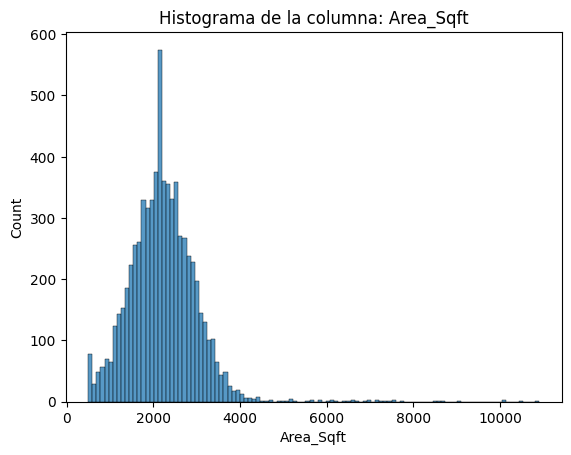

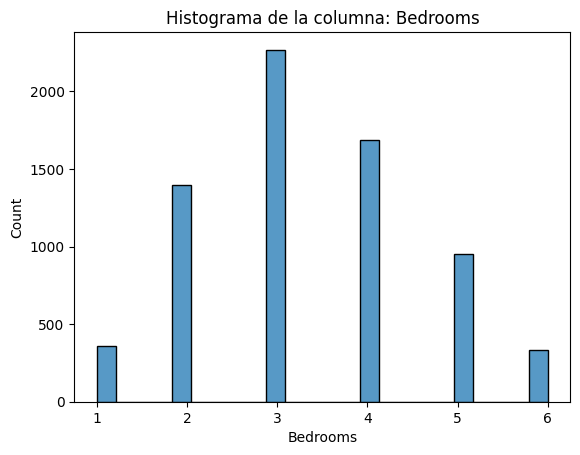

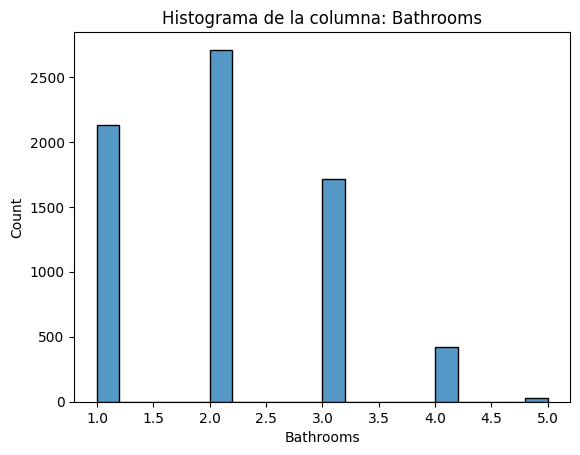

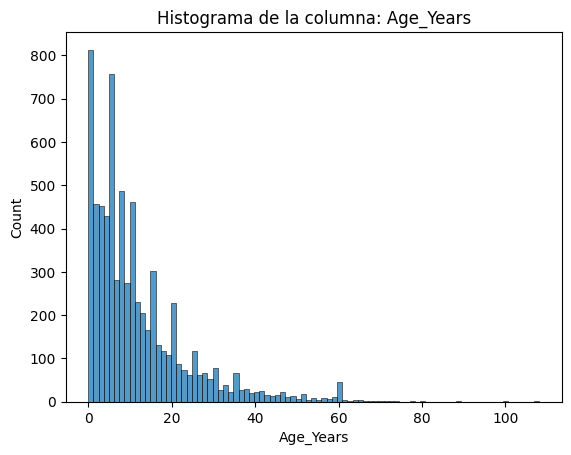

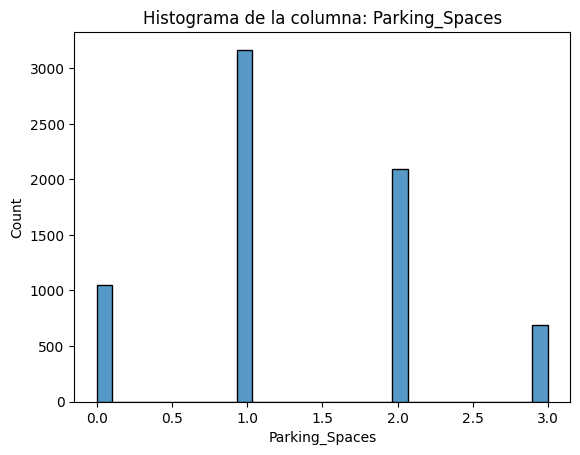

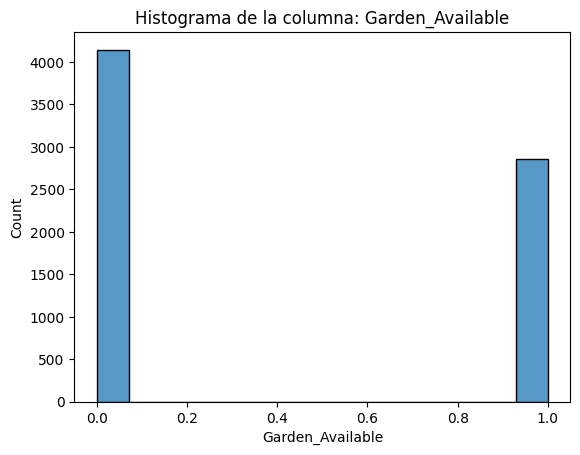

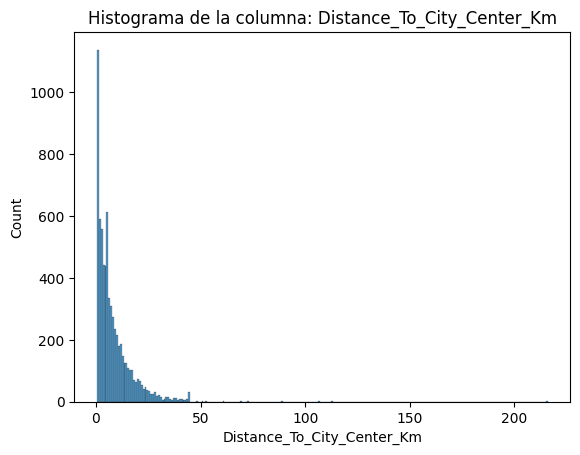

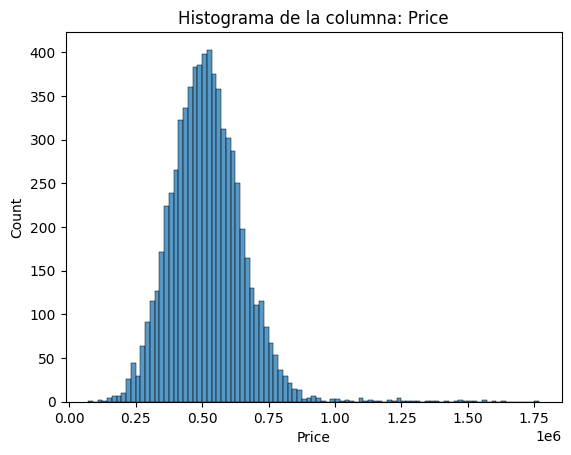

In [ ]:
for col in num_cols:
  if col == "House_ID":
    continue
  else:
    sns.histplot(data=df,x = col)
    plt.title(f"Histograma de la columna: {col}")
    plt.show()


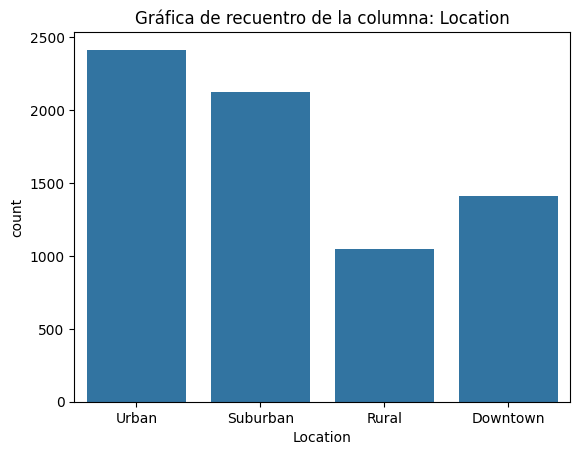

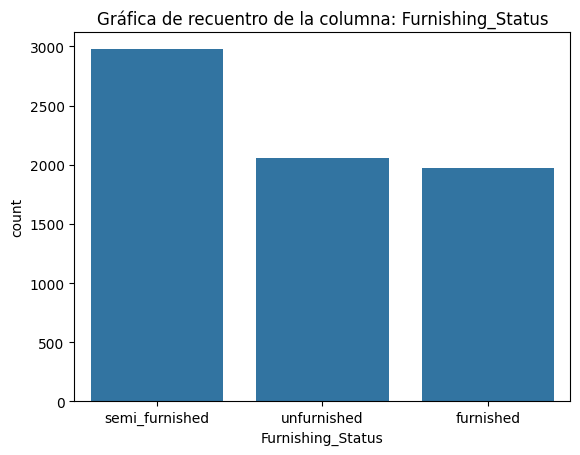

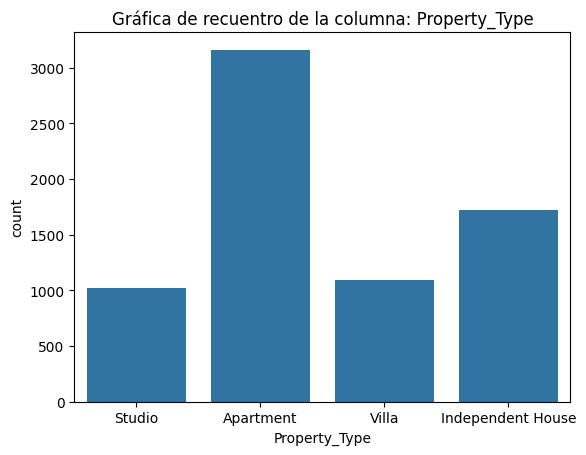

In [ ]:
for col in cat_cols:
  if col == 'Property_Code':
    continue
  else:
    sns.countplot(data =df, x = col)
    plt.title(f"Gráfica de recuentro de la columna: {col}")
    plt.show()

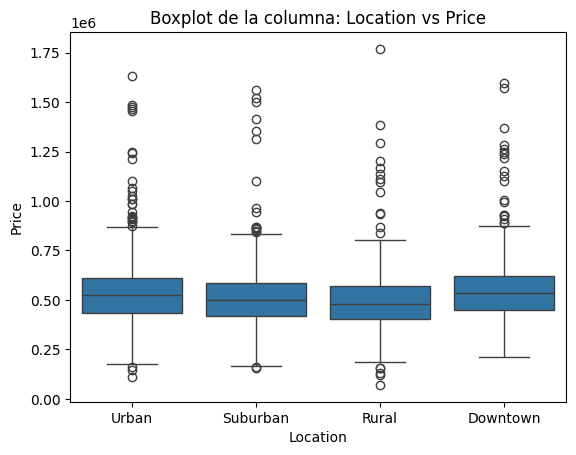

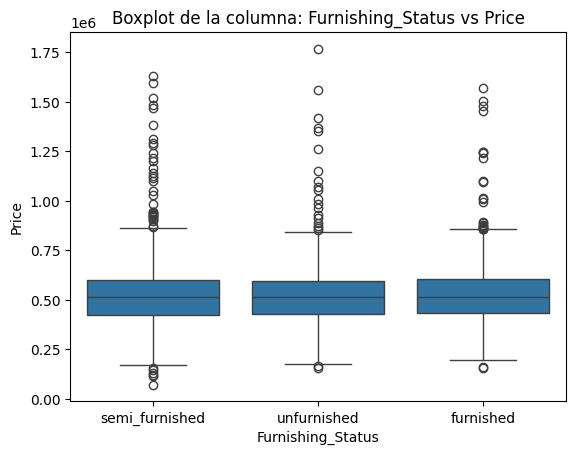

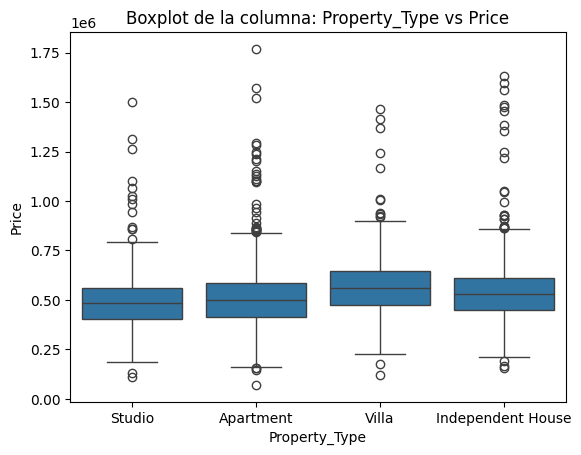

In [ ]:
#Análisis bivariado (relación entre X y Price).
for col in cat_cols:
  if col == "Property_Code":
    continue
  else:
    sns.boxplot(x=col, y='Price', data=df)
    plt.title(f"Boxplot de la columna: {col} vs Price")
    plt.show()

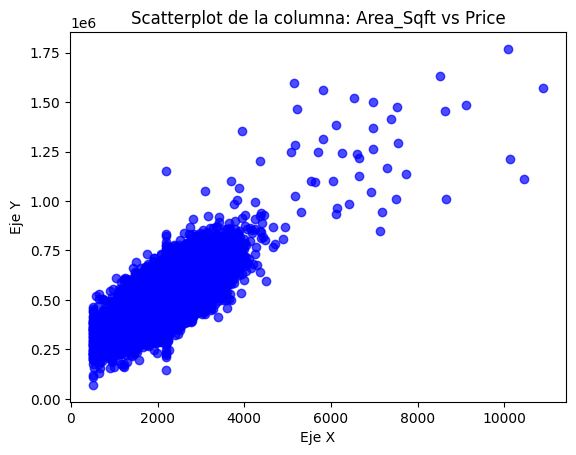

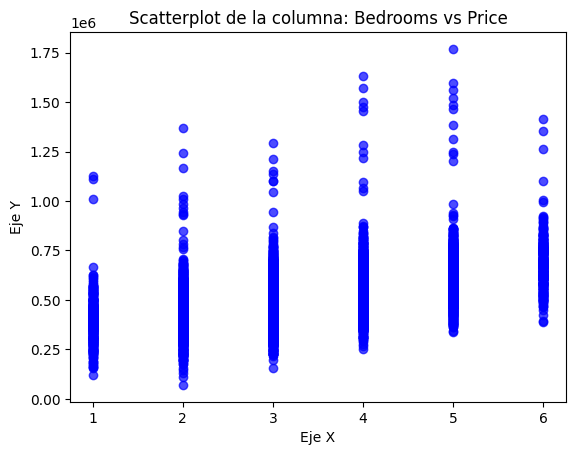

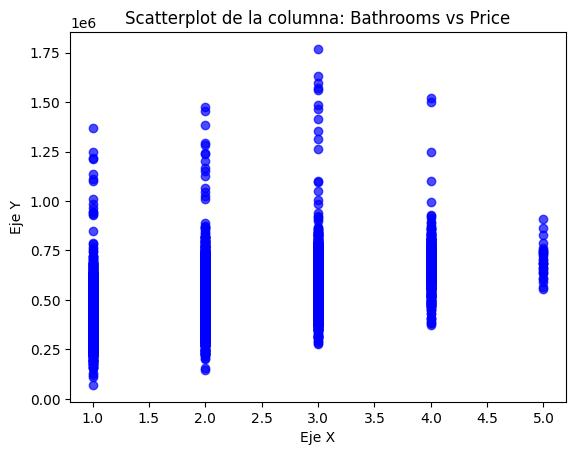

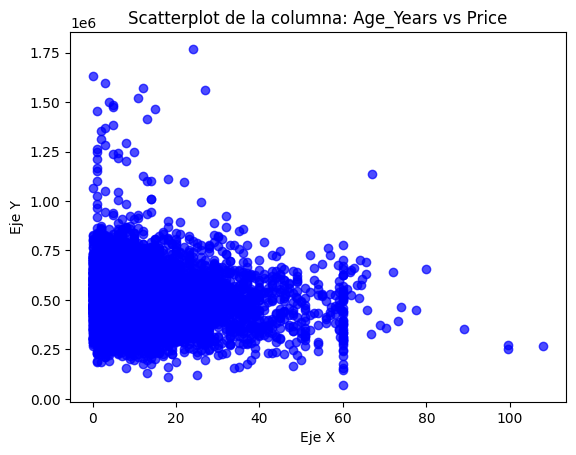

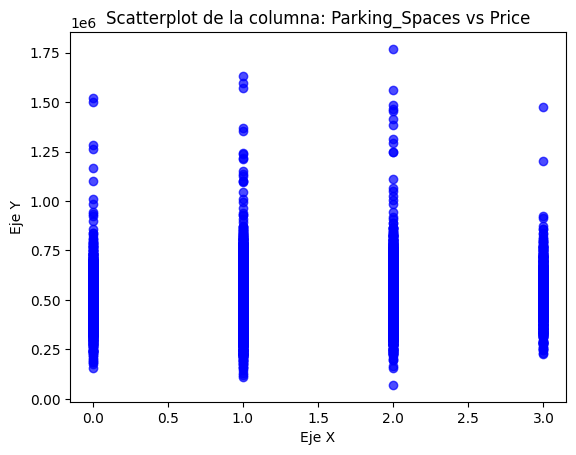

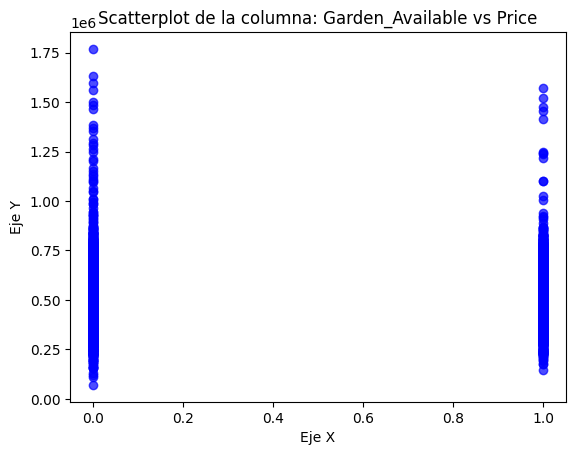

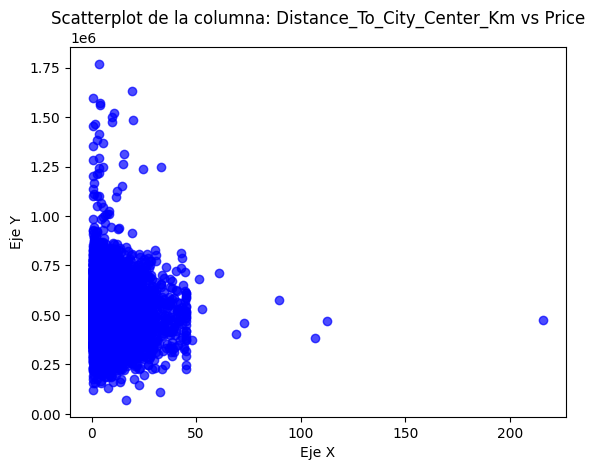

In [ ]:
#Númericas vs Price
for col in num_cols:
  if col == "House_ID" or col == "Price":
    continue
  else:
    plt.scatter(df[col], df['Price'],color='blue',alpha=0.7)
    plt.title(f'Scatterplot de la columna: {col} vs Price')
    plt.xlabel('Eje X')
    plt.ylabel('Eje Y')
    plt.show()

In [ ]:
matriz = df.corr(numeric_only=True)
print(matriz)

                            House_ID  Area_Sqft  Bedrooms  Bathrooms  \
House_ID                    1.000000  -0.027071 -0.009351  -0.004066   
Area_Sqft                  -0.027071   1.000000  0.002168   0.006293   
Bedrooms                   -0.009351   0.002168  1.000000   0.726043   
Bathrooms                  -0.004066   0.006293  0.726043   1.000000   
Age_Years                   0.008369   0.018977 -0.002024  -0.005152   
Parking_Spaces             -0.000807  -0.004723  0.005006   0.007474   
Garden_Available            0.009341  -0.017384  0.006975   0.008206   
Distance_To_City_Center_Km -0.005330   0.007018 -0.000120  -0.001125   
Price                      -0.019975   0.753839  0.527146   0.478970   

                            Age_Years  Parking_Spaces  Garden_Available  \
House_ID                     0.008369       -0.000807          0.009341   
Area_Sqft                    0.018977       -0.004723         -0.017384   
Bedrooms                    -0.002024        0.005006 

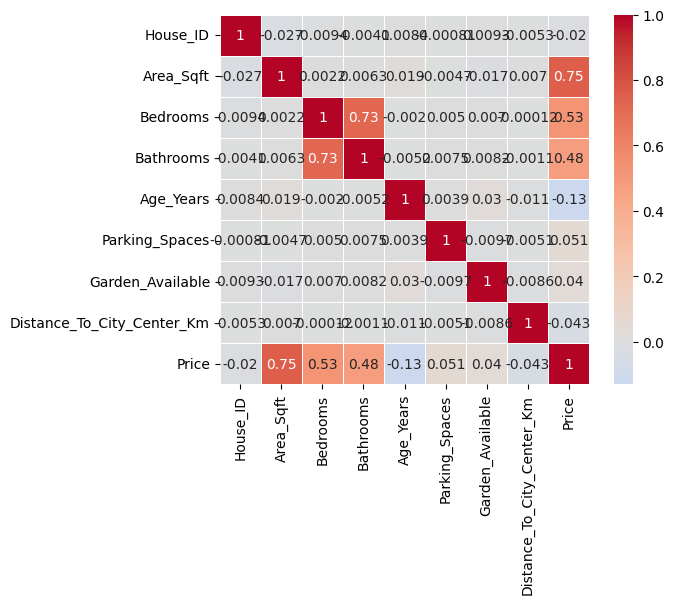

In [ ]:
#Matriz de correlación y multicolinealidad.
sns.heatmap(matriz,
    annot=True,        # Muestra los valores numéricos dentro de las celdas
    cmap="coolwarm",   # Paleta de colores (azul a rojo)
    center=0,          # Centra el mapa de colores en 0
    linewidths=0.5,    # Grosor de las líneas divisorias
    square=True )
plt.show()

In [ ]:
#Hacer el modelo de ML
# 2.1 Separar X e Y
y = df['Price']
X = df.drop(columns=['House_ID','Property_Code','Price'])
print(X)



      Area_Sqft  Bedrooms  Bathrooms  Age_Years  Location Furnishing_Status  \
0        2548.0         1          1        5.0     Urban    semi_furnished   
1        2103.0         2          1        2.0  Suburban    semi_furnished   
2        2653.0         3          2        3.0     Urban    semi_furnished   
3        3266.0         4          3        3.0  Suburban    semi_furnished   
4        2036.0         2          1       16.0     Urban    semi_furnished   
...         ...       ...        ...        ...       ...               ...   
6996     2738.0         1          1        9.0     Urban         furnished   
6997     1831.0         3          1       38.0  Suburban    semi_furnished   
6998     2196.0         5          4       12.0  Downtown         furnished   
6999     2479.0         4          2        1.0  Suburban    semi_furnished   
7019     2133.0         2          2        1.0     Urban    semi_furnished   

          Property_Type  Parking_Spaces  Garden_Ava

In [ ]:
# 2.2 Crear Total_Rooms y eliminar originales
X['rooms'] = X['Bedrooms'] + X['Bathrooms']
X = X.drop(columns=['Bedrooms', 'Bathrooms'])

In [ ]:
# 2.3 One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)



In [ ]:
# 2.4 Train/Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [ ]:
print(f"La forma de X es: {X.shape}")
print(f"La forma de X es: {X_test.shape} y {X_train.shape}")
print(f"La forma de Y es: {y_test.shape} y {y_train.shape}")
print(f"La longitud de train es de: {len(X_train)} y de test: {len(X_test)}")

La forma de X es: (7001, 14)
La forma de X es: (2101, 14) y (4900, 14)
La forma de Y es: (2101,) y (4900,)
La longitud de train es de: 4900 y de test: 2101


In [ ]:
#Importar LinearRegression desde sklearn.linear_model.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

#Instancia modelo
model_lr = LinearRegression()
#Entrenar modelo
model_lr.fit(X_train, y_train)

#Predecir targets en ambos grupos
y_pred_train_lr = model_lr.predict(X_train)
y_pred_test_lr = model_lr.predict(X_test)

#Evaluar modelo
rmse_train_lr = root_mean_squared_error(y_train, y_pred_train_lr)
rmse_test_lr = root_mean_squared_error(y_test, y_pred_test_lr)

#Comunicar
print(f"RMSE train: {rmse_train_lr:.2f}")
print(f"RMSE test: {rmse_test_lr:.2f}")
print(f'La diferencia es de: {rmse_train_lr- rmse_test_lr:.2f}')
print(f"El promedio de Price es:${y.mean():.2f}")


RMSE train: 32776.23
RMSE test: 35791.88
La diferencia es de: -3015.65
El promedio de Price es:$519339.39


## Hallazgo — Regresión Lineal (Baseline)

| Métrica | Valor |
|---|---|
| RMSE train | $32.776 |
| RMSE test | $35.792 |
| Precio medio | $519.339 |
| Error relativo (test) | ~6.9% |

Interpretación:
- La diferencia train/test es de ~9%: no hay overfitting severo.
- El modelo generaliza razonablemente, pero el error (±$35.792) está por
  encima de lo que el negocio consideraría óptimo (±$10.000-15.000).
- Este RMSE se establece como baseline para comparar con Árbol de Decisión
  y Random Forest.


In [ ]:
#Árbol de decisión
from sklearn import tree

# Instanciar el modelo
model_dt = tree.DecisionTreeRegressor(random_state=42)
#Entrenar modelo
model_dt.fit(X_train, y_train)

#Predicción en ambos grupos
y_pred_train_dt = model_dt.predict(X_train)
y_pred_test_dt = model_dt.predict(X_test)

#Calcular RMSE
rmse_train_dt = root_mean_squared_error(y_train, y_pred_train_dt)
rmse_test_dt = root_mean_squared_error(y_test, y_pred_test_dt)

print(f"RMSE train: {rmse_train_dt:.2f}")
print(f"RMSE test: {rmse_test_dt:.2f}")
print(f'La diferencia es de: {rmse_train_dt- rmse_test_dt:.2f}')
print(f"El promedio de Price es:${y.mean():.2f}")

RMSE train: 0.00
RMSE test: 55627.95
La diferencia es de: -55627.95
El promedio de Price es:$519339.39


## Hallazgo — Árbol de Decisión

| Métrica | Valor |
|---|---|
| RMSE train | $0.00 |
| RMSE test | $55.628 |
| Error relativo (test) | ~10.7% |

Diagnóstico: overfitting severo.
- El árbol sin poda crece hasta memorizar cada muestra del train (RMSE = 0).
- En test falla: su error es 55% mayor que el de la Regresión Lineal.
- No supera el baseline.

Implicación para el siguiente paso:
- Este resultado justifica el uso de Random Forest, que entrena muchos
  árboles con subconjuntos aleatorios y promedia sus predicciones,
  reduciendo la varianza y el overfitting.

In [ ]:
#Entrenar Random Forest.
from sklearn.ensemble import RandomForestRegressor

#Instanciar modelo
model_rf = RandomForestRegressor(random_state=42, n_estimators=50)
#Entrenar modelos
model_rf.fit(X_train, y_train)

y_pred_train_rf = model_rf.predict(X_train)
y_pred_test_rf = model_rf.predict(X_test)

rmse_train_rf =root_mean_squared_error(y_train, y_pred_train_rf)
rmse_test_rf = root_mean_squared_error(y_test, y_pred_test_rf)

print(f"RMSE train: {rmse_train_rf:.2f}")
print(f"RMSE test: {rmse_test_rf:.2f}")
print(f'La diferencia es de: {rmse_train_rf- rmse_test_rf:.2f}')
print(f"El promedio de Price es:${y.mean():.2f}")

RMSE train: 15666.90
RMSE test: 40892.81
La diferencia es de: -25225.91
El promedio de Price es:$519339.39


## Hallazgo — Random Forest

| Métrica | Valor |
|---|---|
| RMSE train | $15.667 |
| RMSE test | $40.893 |
| Error relativo (test) | ~7.9% |

Comparativa de los 3 modelos:
| Modelo | RMSE train | RMSE test |
|---|---|---|
| Regresión Lineal | $32.776 | $35.792 |
| Árbol de Decisión | $0.00 | $55.628 |
| Random Forest | $15.667 | $40.893 |

Diagnóstico:
- Random Forest reduce el overfitting del Árbol individual (40.893 < 55.628).
- Pero NO supera a la Regresión Lineal (40.893 > 35.792).
- Sigue habiendo overfitting (train 15.667 vs test 40.893).

Interpretación de negocio:
- En este dataset, la relación Price ← X es esencialmente lineal.
- Area_Sqft (r = 0.75, relación lineal) domina la señal.
- Random Forest añade varianza sin capturar más señal.

Implicación para F-6:
- Ajustar hiperparámetros de Random Forest (max_depth, min_samples_leaf).
- Probar log(Price).
- El baseline de Regresión Lineal sigue siendo el mejor hasta ahora.

In [ ]:
#Cross Validation
from sklearn.model_selection import cross_val_score
import numpy as np

# Aplicar a cada modelo
scores_lr = cross_val_score(model_lr, X, y,cv=10, scoring='neg_mean_squared_error')
scores_dt = cross_val_score(model_dt, X, y, cv=10, scoring='neg_mean_squared_error')
scores_rf = cross_val_score(model_rf, X, y, cv=10, scoring='neg_mean_squared_error')

# Reportar

for nombre, scores in [('Regresión Lineal', scores_lr),
                        ('Árbol de Decisión', scores_dt),
                        ('Random Forest', scores_rf)]:
  rmse_scores = np.sqrt(-scores)
  print(f"{nombre}: RMSE promedio = ${rmse_scores.mean():.2f},   "
        f"desviación = ${rmse_scores.std():.2f}")

Regresión Lineal: RMSE promedio = $33693.13,   desviación = $3094.29
Árbol de Decisión: RMSE promedio = $58265.53,   desviación = $4320.48
Random Forest: RMSE promedio = $39839.78,   desviación = $2194.44


## Hallazgo — Validación Cruzada (5-fold)

| Modelo | RMSE CV promedio | Desviación estándar |
|---|---|---|
| Regresión Lineal | $33.693 | $3.094 |
| Árbol de Decisión | $58.266 | $4.320 |
| Random Forest | $39.840 | $2.194 |

Interpretación:
- La validación cruzada CONFIRMA el resultado de F-5: Regresión Lineal
  es el mejor modelo de los tres.
- Regresión Lineal: RMSE promedio $33.693, estable entre folds.
- Random Forest: menor desviación ($2.194), pero peor RMSE promedio.
- Árbol de Decisión: peor en ambos criterios.

Conclusión: el resultado de F-5 no fue suerte. Regresión Lineal es
consistentemente el mejor modelo para este dataset.

In [ ]:
# Ajuste de hiperparámetros de Random Forest.
configuraciones = [
    {'n_estimators':100, 'max_depth':5},
    {'n_estimators':100, 'max_depth':10},
    {'n_estimators':100, 'max_depth':None, 'min_samples_leaf':10},
    {'n_estimators':200, 'max_depth':10, 'min_samples_leaf':5}
]

for config in configuraciones:
  model = RandomForestRegressor(random_state= 42, **config)
  model.fit(X_train, y_train)
  rmse_train = root_mean_squared_error(y_train, model.predict(X_train))
  rmse_test = root_mean_squared_error(y_test, model.predict(X_test))
  print(f"{config} train: ${rmse_train:.2f}, test: ${rmse_test:.2f}")

{'n_estimators': 100, 'max_depth': 5} train: $51997.80, test: $56691.45
{'n_estimators': 100, 'max_depth': 10} train: $26748.77, test: $41940.20
{'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 10} train: $37429.41, test: $44985.99
{'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 5} train: $32505.07, test: $42797.02


## Hallazgo — Ajuste de hiperparámetros de Random Forest

| Configuración | RMSE train | RMSE test |
|---|---|---|
| max_depth=5 | $51.998 | $56.691 |
| max_depth=10 | $26.749 | $41.940 |
| max_depth=None, min_samples_leaf=10 | $37.429 | $44.986 |
| n_estimators=200, max_depth=10, min_samples_leaf=5 | $32.505 | $42.797 |
| Regresión Lineal (baseline) | $32.776 | $35.792 |

Diagnóstico:
- Ninguna configuración de Random Forest supera a Regresión Lineal.
- max_depth=5 → underfitting (modelo demasiado simple).
- max_depth=10 → mejor RF, pero sigue por encima del baseline.
- Trade-off sesgo-varianza confirmado.

Conclusión: Random Forest no es el modelo adecuado para este dataset.

# Fase 7 Comunicar Hallazgos

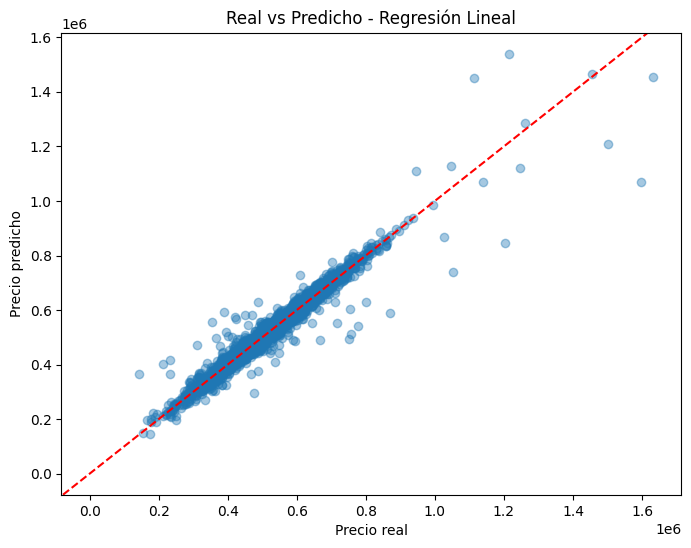

In [ ]:
#Visualizaciones clave.
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_test_lr, alpha=0.4)
plt.axline((0,0), slope=1, color='red', linestyle='--')
plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.title('Real vs Predicho - Regresión Lineal')
plt.show()


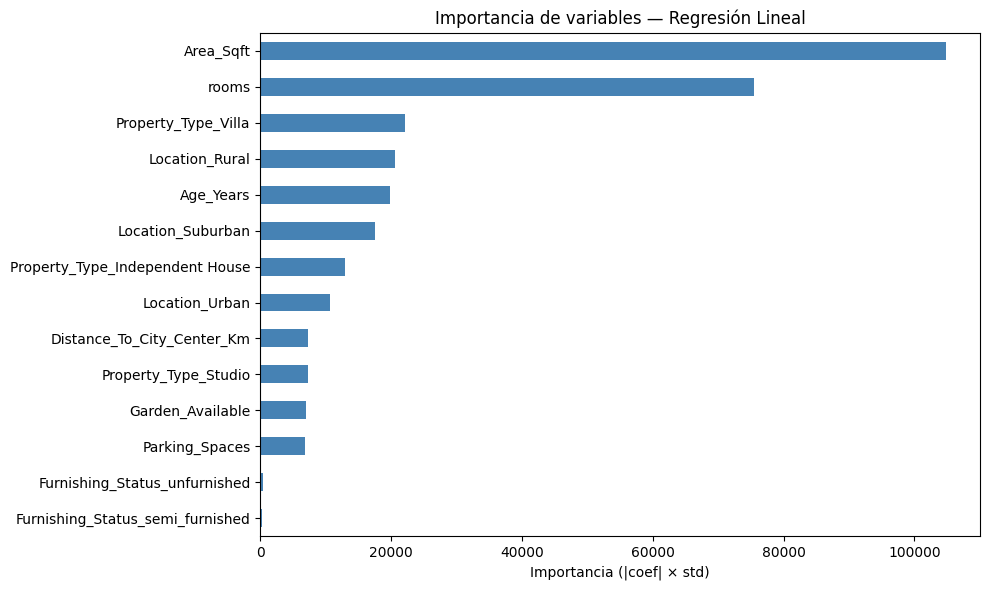

In [ ]:
#Importancia de variables
coef = pd.Series(model_lr.coef_, index=X_train.columns)

# Importancia corregida: |coef| * std(X)
importancia = (coef.abs() * X_train.std()).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importancia.plot(kind='barh', color='steelblue')
plt.xlabel('Importancia (|coef| × std)')
plt.title('Importancia de variables — Regresión Lineal')
plt.tight_layout()
plt.savefig('04_importancia_variables.png', dpi=150, bbox_inches='tight')
plt.show()